### Prof. Alfio Ferrara

# Il contesto

##  Metodologie informatiche nelle discipline umanistiche
##### A.A. 2026/2027

---

Nel notebook precedente abbiamo visto che ogni parola può avere un vettore appreso. Ma quei vettori dipendevano dal compito: li avevamo ottenuti per prevedere il **clima** di una città, con cinque etichette decise da una persona. Le posizioni riflettevano solo quelle cinque classi.

Ora cambiamo il compito, e non servono più etichette. Il testo stesso ci dà il problema da risolvere: **indovinare una parola guardando le parole che le stanno intorno**. Il significato generale di una parola, ci aspettiamo, è nel modo in cui viene usata.

## Il contesto di una parola

Il **contesto** di una parola è l'insieme delle parole vicine, nella stessa frase. Fissiamo una finestra di due parole prima e due dopo. Ogni posizione di ogni frase diventa un esempio: le parole intorno sono l'ingresso, la parola in mezzo è quella da indovinare.

Usiamo gli stessi cento testi sulle città, divisi in frasi.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

with open('data/clima_citta.json') as f:
    dataset = json.load(f)

classi_clima = ['tropicale', 'desertico', 'mediterraneo', 'temperato', 'polare']

frasi, doc_della_frase = [], []
for i, voce in enumerate(dataset):
    for frase in re.split(r'[.!?;]', voce['testo']):
        parole_frase = re.findall(r'[^\W\d_]+', frase.lower())
        if len(parole_frase) >= 3:
            frasi.append(parole_frase)
            doc_della_frase.append(i)

vocabolario = sorted({p for frase in frasi for p in frase})
posizione = {p: j for j, p in enumerate(vocabolario)}
V = len(vocabolario)

FINESTRA = 2
esempi = []
for frase, i in zip(frasi, doc_della_frase):
    for k, parola in enumerate(frase):
        contesto = [frase[j] for j in range(max(0, k - FINESTRA), min(len(frase), k + FINESTRA + 1)) if j != k]
        esempi.append((contesto, posizione[parola], i))

print(len(frasi), 'frasi,', sum(len(f) for f in frasi), 'parole,', V, 'parole diverse')
print('esempi (contesto → parola):', len(esempi))
print('\nfrase:', ' '.join(frasi[0]), '\n')
print(pd.DataFrame({'contesto': [' '.join(c) for c, _, _ in esempi[:8]],
                    'parola da indovinare': [vocabolario[t] for _, t, _ in esempi[:8]]}).to_string())

200 frasi, 2943 parole, 614 parole diverse
esempi (contesto → parola): 2943

frase: a singapore fa caldo e umido tutto l anno con temperature che variano di poco tra una stagione e l altra 

               contesto parola da indovinare
0          singapore fa                    a
1            a fa caldo            singapore
2   a singapore caldo e                   fa
3  singapore fa e umido                caldo
4  fa caldo umido tutto                    e
5       caldo e tutto l                umido
6        e umido l anno                tutto
7  umido tutto anno con                    l


## Un momento di riflessione

- Quante parole di contesto ha ogni esempio? Perché le prime e le ultime parole di una frase ne hanno meno?
- Per ogni parola della frase abbiamo un esempio. Quanti esempi ha una parola molto frequente come *e*? E una rara come il nome di una città?
- Chi ha deciso la «risposta giusta» di ogni esempio? Serve una persona per etichettarli?
- Se due parole compaiono con gli stessi vicini, che cosa possiamo dire del modo in cui sono usate?
- La finestra è di due parole. Che cosa cambierebbe con una finestra di una sola parola o di una frase intera?

## Predire una parola dal contesto

La rete è la stessa di prima, con tre differenze.

1. **L'ingresso è il contesto**: un vettore con una componente per ogni parola del vocabolario, uguale alla frazione delle parole di contesto che sono quella parola. Le parole di contesto contano allo stesso modo, qualunque posizione abbiano.
2. **Il livello intermedio ha 16 dimensioni**, invece di 2, e non ha funzione di attivazione: è la **media delle righe di $W_1$** delle parole di contesto, cioè dei loro vettori.
3. **L'uscita ha una classe per ogni parola** del vocabolario: la rete assegna una probabilità a ogni parola possibile, con la softmax.

$$h = xW_1 \qquad p = \text{softmax}(hW_2 + b_2)$$

Il compito è sempre quello di far salire la probabilità della parola giusta, con lo stesso errore $-\ln p$ e la stessa discesa del gradiente. Prima del training i parametri sono casuali.

In [3]:
X = np.zeros((len(esempi), V))
for n, (contesto, _, _) in enumerate(esempi):
    for p in contesto:
        X[n, posizione[p]] += 1 / len(contesto)
y = np.array([t for _, t, _ in esempi])

def softmax(s):
    e = np.exp(s - s.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)

def inizializza(n_nascosti=16, seed=0):
    rng = np.random.default_rng(seed)
    return {'W1': rng.normal(scale=0.1, size=(V, n_nascosti)), 'W2': rng.normal(scale=0.1, size=(n_nascosti, V)), 'b2': np.zeros(V)}

def probabilita(par, X):
    return softmax(X @ par['W1'] @ par['W2'] + par['b2'])

def vettore_contesto(contesto):
    x = np.zeros(V)
    for p in contesto:
        x[posizione[p]] += 1 / len(contesto)
    return x

def prevedi(par, contesti, k=3):
    p = probabilita(par, np.array([vettore_contesto(c) for c in contesti]))
    righe = []
    for c, riga in zip(contesti, p):
        migliori = np.argsort(-riga)[:k]
        righe.append([' '.join(c)] + [f'{vocabolario[j]} ({riga[j]:.2f})' for j in migliori])
    return pd.DataFrame(righe, columns=['contesto'] + [f'{i + 1}ª' for i in range(k)])

contesti_prova = [
    ['fa', 'caldo', 'umido', 'tutto'],
    ['clima', 'e', 'umido', 'tutto'],
    ['estati', 'e', 'inverni', 'sono'],
    ['inverni', 'molto', 'lunghi', 'e'],
    ['il', 'clima', 'è', 'secco'],
]

par = inizializza()
print('W1:', par['W1'].shape, '| W2:', par['W2'].shape, '| parametri:', sum(v.size for v in par.values()))
print('probabilità se tutte le parole fossero equiprobabili:', round(1 / V, 4))
print()
print(prevedi(par, contesti_prova).to_string(index=False))

W1: (614, 16) | W2: (16, 614) | parametri: 20262
probabilità se tutte le parole fossero equiprobabili: 0.0016

              contesto                        1ª                2ª                 3ª
  fa caldo umido tutto           santiago (0.00) soleggiata (0.00)   frequenza (0.00)
   clima e umido tutto                 su (0.00)  invernali (0.00)  riflettono (0.00)
 estati e inverni sono            periodi (0.00)       nell (0.00)        nord (0.00)
inverni molto lunghi e            marcate (0.00)  ilulissat (0.00) vegetazione (0.00)
      il clima è secco insopportabilmente (0.00)  temporali (0.00)     marcate (0.00)


## Un momento di riflessione

- Quanti parametri ha la rete, rispetto a quella del notebook precedente? Da dove viene la differenza?
- Le previsioni prima del training sono ragionevoli? Quale probabilità ha ciascuna parola, rispetto a quella di una scelta a caso?
- Il livello intermedio è la media dei vettori delle parole di contesto. Che cosa succede se due contesti hanno le stesse parole in ordine diverso?
- Perché l'uscita ha una classe per ogni parola e non cinque come prima? Che cosa abbiamo tolto dal compito?

## Il training

Alleniamo con la discesa del gradiente su tutti gli esempi, 300 passi con $\eta = 20$. Senza funzione di attivazione le formule del gradiente sono quelle di prima, più semplici: non c'è la derivata della $\tanh$.

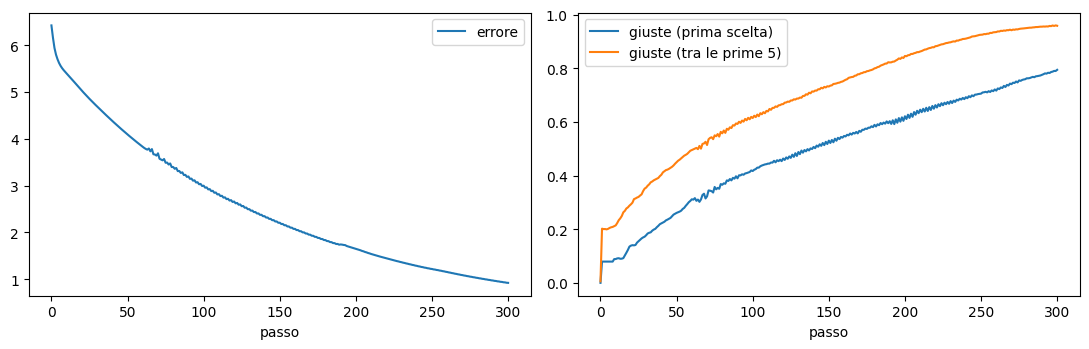

     errore  giuste (prima scelta)  giuste (tra le prime 5)
0     6.421                  0.001                    0.006
100   2.999                  0.417                    0.615
200   1.651                  0.621                    0.846
300   0.925                  0.794                    0.958


In [4]:
def addestra(par, X, y, eta=20.0, passi=300):
    par = {k: v.copy() for k, v in par.items()}
    Y = np.zeros((len(y), V))
    Y[np.arange(len(y)), y] = 1
    storia = []
    for _ in range(passi + 1):
        h = X @ par['W1']
        p = softmax(h @ par['W2'] + par['b2'])
        storia.append({'errore': -np.log(p[np.arange(len(y)), y]).mean(),
                       'giuste (prima scelta)': (p.argmax(axis=1) == y).mean(),
                       'giuste (tra le prime 5)': (np.argsort(-p, axis=1)[:, :5] == y[:, None]).any(axis=1).mean()})
        ds = (p - Y) / len(y)
        dh = ds @ par['W2'].T
        par['W2'] -= eta * h.T @ ds
        par['b2'] -= eta * ds.sum(axis=0)
        par['W1'] -= eta * X.T @ dh
    return par, pd.DataFrame(storia)

par_finale, storia = addestra(par, X, y)

fig, assi = plt.subplots(1, 2, figsize=(11, 3.6))
storia[['errore']].plot(ax=assi[0])
storia[['giuste (prima scelta)', 'giuste (tra le prime 5)']].plot(ax=assi[1])
for ax in assi:
    ax.set_xlabel('passo')
plt.tight_layout()
plt.show()

print(storia.iloc[[0, 100, 200, 300]].round(3).to_string())

## Un momento di riflessione

- Dopo 300 passi, quante volte la rete indovina la parola con la prima scelta? E tra le prime cinque?
- Indovinare la parola esatta è sempre possibile? Quando il contesto lascia più parole plausibili, ha senso pretendere di arrivare al 100%?
- L'errore è calcolato sugli stessi esempi usati per imparare. Quanto possiamo fidarci dei numeri? Che cosa potrebbe aver fatto la rete, con 20 mila parametri e meno di 3 mila esempi?
- Rispetto alle etichette dei climi, che cosa è cambiato nella quantità di «risposte giuste» a disposizione per imparare?

## Dopo il training: contesti nuovi

Rifacciamo le previsioni sugli stessi contesti di prima. Il primo è una frase vera del corpus, gli altri sono inventati: la rete non li ha mai visti uguali.

In [5]:
print(prevedi(par_finale, contesti_prova).to_string(index=False))

              contesto              1ª             2ª             3ª
  fa caldo umido tutto        e (0.82)   caldo (0.08)    dove (0.03)
   clima e umido tutto    caldo (0.97)   calde (0.01)   calda (0.01)
 estati e inverni sono moderate (0.49) tiepide (0.37) fresche (0.08)
inverni molto lunghi e   freddi (0.54)  mentre (0.10)    gelo (0.10)
      il clima è secco    caldo (0.93)       e (0.05)   avana (0.00)


## Un momento di riflessione

- Per il primo contesto, che è nel corpus, la rete è sicura? Che cosa potrebbe aver fatto, in questo caso, più che «capire»?
- Per i contesti inventati le previsioni sono sensate? Che tipo di parola mette al primo posto?
- Che cosa hanno in comune le parole tra le prime tre scelte di uno stesso contesto? Sono interscambiabili in quella frase?
- In «il clima è secco» la rete risponde *caldo*. È una risposta ragionevole? Che cosa ci dice sui dati con cui ha imparato?
- Per indovinare *caldo* o *freddi* la rete ha dovuto imparare qualcosa su di loro. Dove sta quello che ha imparato?

## I vettori delle parole

Quello che la rete ha imparato sta nelle righe di $W_1$: ogni parola ha ora un vettore di 16 numeri. Il vettore di una parola è appreso solo per fare bene il compito di indovinare parole dal contesto, ma può servire a molto altro. Per confrontare due vettori usiamo la **similarità del coseno**, come per i documenti. Guardiamo le parole più vicine a quelle scelte. Per confronto calcoliamo gli stessi vicini con un'altra rete: quella del notebook precedente, con 16 nodi nascosti e addestrata a classificare i climi (il **vettore per classe**).

In [6]:
conteggi = np.zeros((len(dataset), V))
for frase, i in zip(frasi, doc_della_frase):
    for p in frase:
        conteggi[i, posizione[p]] += 1
idf = np.log(len(dataset) / (conteggi > 0).sum(axis=0))
tfidf_doc = conteggi / conteggi.sum(axis=1, keepdims=True) * idf
tfidf_doc /= np.maximum(np.linalg.norm(tfidf_doc, axis=1, keepdims=True), 1e-12)
y_classi = np.array([classi_clima.index(v['clima']) for v in dataset])

def addestra_classi(n_nascosti=16, eta=2.0, passi=300, seed=0):
    rng = np.random.default_rng(seed)
    W1 = rng.normal(scale=0.1, size=(V, n_nascosti)); b1 = np.zeros(n_nascosti)
    W2 = rng.normal(scale=0.1, size=(n_nascosti, 5)); b2 = np.zeros(5)
    Y = np.eye(5)[y_classi]
    for _ in range(passi + 1):
        h = np.tanh(tfidf_doc @ W1 + b1)
        p = softmax(h @ W2 + b2)
        ds = (p - Y) / len(Y)
        dz = (ds @ W2.T) * (1 - h ** 2)
        W1 -= eta * tfidf_doc.T @ dz; b1 -= eta * dz.sum(axis=0)
        W2 -= eta * h.T @ ds; b2 -= eta * ds.sum(axis=0)
    return W1, (p.argmax(axis=1) == y_classi).mean()

vettori_classe, accuratezza_classi = addestra_classi()
vettori_contesto = par_finale['W1']
print(f'rete per classe: accuratezza sui cento documenti {accuratezza_classi:.2f}\n')

def normalizza(E):
    return E / np.maximum(np.linalg.norm(E, axis=1, keepdims=True), 1e-9)

def vicine(E, parola, k=5):
    sim = normalizza(E) @ normalizza(E)[posizione[parola]]
    return [vocabolario[j] for j in np.argsort(-sim)[1:k + 1]]

scelte = ['umido', 'giugno', 'freddi', 'caldo', 'inverni', 'singapore']
print(pd.DataFrame({
    'parola': scelte,
    'vicine, vettore per classe': [', '.join(vicine(vettori_classe, p)) for p in scelte],
    'vicine, vettore da contesto': [', '.join(vicine(vettori_contesto, p)) for p in scelte],
}).to_string(index=False))

rete per classe: accuratezza sui cento documenti 1.00

   parola                        vicine, vettore per classe                    vicine, vettore da contesto
    umido          delle, primavera, umidità, intensi, alla       afoso, secco, soleggiata, vite, asciutte
   giugno  addolcite, umidità, dagli, pomeridiani, coincide permafrost, maggio, luglio, tifoni, escursione
   freddi    latitudine, regolari, paese, tiepide, distinte        tundra, gelidi, rigidi, lunghissimi, la
    caldo elevata, acquazzoni, temporali, allagano, umidità                tramonta, sul, d, terreno, sole
  inverni                mare, ha, dal, persistente, estati  svalbard, zurigo, acquazzoni, parigi, abidjan
singapore              regola, ushuaia, tregua, manila, qui    praga, reykjavik, scirocco, cade, fairbanks


## Un momento di riflessione

- Con il vettore per classe, le parole vicine che cosa hanno in comune con quella scelta? E con quello da contesto?
- Per *giugno* e *umido*, quali vicine vi sembrano più sensate? *giugno* è vicina a *maggio* e *luglio*: la rete sa che sono mesi? Che cosa ha osservato, davvero?
- Il vettore per classe poteva sapere che *maggio* e *giugno* sono mesi? Le cinque etichette contenevano questa informazione?
- Alcune vicine sono sbagliate o poco significative (le parole poco frequenti sono rumorose). Che cosa servirebbe per avere vettori più affidabili?
- Tra le vicine di *caldo* ci sono parole che avremmo voluto vedere? Quali mancano? Perché?

## Misurare la somiglianza grammaticale

Per avere un numero, e non solo qualche esempio, contiamo quante delle cinque parole più vicine hanno la stessa **categoria grammaticale** (nome, aggettivo, verbo, preposizione, ...) della parola di partenza. Le categorie le assegna spaCy, che la rete non ha mai visto. Consideriamo le parole che compaiono almeno quattro volte. Come riferimento, vettori casuali.

In [7]:
import spacy
nlp = spacy.load('it_core_news_lg')

categoria = {}
for frase in frasi:
    for t in nlp(' '.join(frase)):
        categoria.setdefault(t.text, t.pos_)
categorie = np.array([categoria.get(p, 'X') for p in vocabolario])
frequenza = np.bincount(y, minlength=V)
frequenti = np.flatnonzero(frequenza >= 4)

def quota_stessa_categoria(E, k=5):
    En = normalizza(E)[frequenti]
    sim = En @ En.T
    np.fill_diagonal(sim, -9)
    vicini = np.argsort(-sim, axis=1)[:, :k]
    return np.mean(categorie[frequenti][vicini] == categorie[frequenti][:, None])

casuali = np.random.default_rng(0).normal(size=(V, 16))
print(pd.Series({'vettori casuali': quota_stessa_categoria(casuali),
                 'vettore per classe': quota_stessa_categoria(vettori_classe),
                 'vettore da contesto': quota_stessa_categoria(vettori_contesto)}).round(2).to_string())
print('\nparole considerate:', len(frequenti))
print(pd.Series(categorie[frequenti]).value_counts().to_string())

vettori casuali        0.17
vettore per classe     0.24
vettore da contesto    0.35

parole considerate: 148
NOUN     44
ADJ      39
ADP      18
VERB     16
DET      12
ADV       9
NUM       3
PRON      2
CCONJ     2
AUX       2
SCONJ     1


## Un momento di riflessione

- Le tre quote sono molto diverse? Qual è la più alta, e di quanto supera il caso?
- Nessuno ha detto alla rete che *umido* è un aggettivo e *giugno* è un nome. Come ha ottenuto una somiglianza grammaticale?
- Perché il vettore per classe è più vicino al caso? A quale informazione dei testi non poteva accedere?
- La quota non arriva vicino a 1. Che cosa limita il risultato: pochi dati, poche dimensioni, un compito troppo semplice?

## Le parole nel piano

Proiettiamo i vettori da contesto a 16 dimensioni in due, con la direzione di massima variazione (PCA), come per i documenti. Le parole sono colorate secondo la categoria grammaticale.

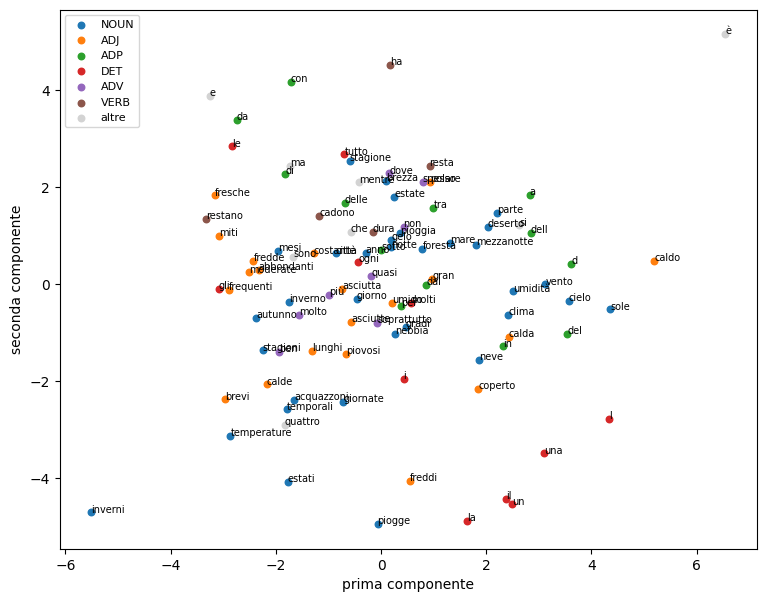

In [8]:
comuni = np.flatnonzero(frequenza >= 6)
E = vettori_contesto[comuni] - vettori_contesto[comuni].mean(axis=0)
_, _, Vt = np.linalg.svd(E, full_matrices=False)
piano = E @ Vt[:2].T

cat_comuni = categorie[comuni]
principali = [c for c in pd.Series(cat_comuni).value_counts().index[:6]]
colori = dict(zip(principali, plt.cm.tab10.colors))

fig, ax = plt.subplots(figsize=(9, 7))
for c in principali:
    m = cat_comuni == c
    ax.scatter(piano[m, 0], piano[m, 1], s=22, color=colori[c], label=c)
altri = ~np.isin(cat_comuni, principali)
ax.scatter(piano[altri, 0], piano[altri, 1], s=22, color='lightgray', label='altre')
for k, j in enumerate(comuni):
    ax.text(piano[k, 0], piano[k, 1], vocabolario[j], fontsize=7)
ax.legend(fontsize=8)
ax.set_xlabel('prima componente')
ax.set_ylabel('seconda componente')
plt.show()

## Un momento di riflessione

- I colori formano gruppi? Quali categorie sono più separate e quali più mescolate?
- Nella proiezione si perde molta informazione: da 16 numeri a 2. Perché una vicinanza nel piano non garantisce una vicinanza nello spazio a 16 dimensioni?
- Nel notebook precedente il piano divideva le parole per clima. Qui divide le parole per... che cosa? Come si spiega?
- Se avessimo molte più frasi, cento volte quelle che abbiamo, che cosa ci aspettiamo che cambi?

## Dalla parola ai suoi vicini: la Commedia

Finora il contesto era l'ingresso e la parola in mezzo l'uscita. Possiamo anche **invertire il compito**: dato una parola, indovinare *una* delle parole che le stanno vicino. Ogni parola, con ciascuno dei suoi vicini entro tre posizioni, forma un esempio. Il livello intermedio non fa più nessuna media: è semplicemente la riga di $W_1$ della parola di ingresso.

$$h = W_1[\text{parola}] \qquad p = \text{softmax}(hW_2 + b_2)$$

Cambiamo anche il testo: la *Commedia* di Dante, cento canti e circa centomila parole. Tenendo le parole che compaiono almeno cinque volte, abbiamo più di cinquecentomila coppie *parola → vicina*. Due accorgimenti pratici:

- le parole molto frequenti (*e*, *che*, *la*) comparirebbero in quasi tutte le coppie: ne scartiamo a caso una parte, tanto più quanto sono frequenti;
- con mezzo milione di esempi non aggiorniamo i pesi dopo averli visti tutti, ma ogni 128 coppie (**mini-lotti**), ripetendo più giri sui dati (**epoche**).

In [9]:
import glob, collections

PERCORSO_COMMEDIA = '/Users/Flint/Data/narrative/commedia'

canti, nomi_canti = [], []
for percorso in sorted(glob.glob(f'{PERCORSO_COMMEDIA}/*.md')):
    with open(percorso) as f:
        testo = f.read().split('\n', 1)[1]
    testo = re.sub(r'^\s*\d+\.', '', testo, flags=re.M).lower()
    canti.append(re.findall(r"[^\W\d_]+", testo))
    nomi_canti.append(percorso.split('/')[-1].split('_')[0])

freq_forme = collections.Counter(p for canto in canti for p in canto)
vocabolario_d = sorted(p for p, n in freq_forme.items() if n >= 5)
posizione_d = {p: j for j, p in enumerate(vocabolario_d)}
V_d = len(vocabolario_d)
frequenza_d = np.array([freq_forme[p] for p in vocabolario_d])

FINESTRA_D = 3
centri, vicine_ = [], []
for canto in canti:
    ids = [posizione_d[p] for p in canto if p in posizione_d]
    for k, i in enumerate(ids):
        for j in range(max(0, k - FINESTRA_D), min(len(ids), k + FINESTRA_D + 1)):
            if j != k:
                centri.append(i)
                vicine_.append(ids[j])
centri, vicine_ = np.array(centri), np.array(vicine_)

print(len(canti), 'canti,', sum(len(c) for c in canti), 'parole,', len(freq_forme), 'forme,', V_d, 'con almeno 5 occorrenze')
print('esempi (parola → vicina):', len(centri))
print('\nprimo verso:', ' '.join(canti[0][:7]), '\n')
print(pd.DataFrame({'parola': [vocabolario_d[i] for i in centri[:8]],
                    'vicina da indovinare': [vocabolario_d[j] for j in vicine_[:8]]}).to_string())

100 canti, 101615 parole, 12848 forme, 2111 con almeno 5 occorrenze
esempi (parola → vicina): 512040

primo verso: nel mezzo del cammin di nostra vita 

  parola vicina da indovinare
0    nel                mezzo
1    nel                  del
2    nel               cammin
3  mezzo                  nel
4  mezzo                  del
5  mezzo               cammin
6  mezzo                   di
7    del                  nel


## Un momento di riflessione

- Ogni parola ha ora tanti esempi quanti sono i suoi vicini. Quale parola è presente in più coppie, una frequente come *e* o una rara come *Beatrice*?
- Per una stessa parola, il compito ha *una sola* risposta giusta? Con quali risposte diverse viene mostrata la stessa parola nelle coppie?
- Che cosa fa la rete se, per la stessa parola, le vicine «giuste» sono dieci diverse? A quale probabilità può puntare per ciascuna?
- Che cosa abbiamo perso rispetto a prima, e che cosa abbiamo guadagnato? Ricordate che la media dei vettori non teneva conto dell'ordine.

## Il training sulla Commedia

Questa volta il vettore di ogni parola ha 32 dimensioni. Il training è lo stesso: errore $-\ln p$ e discesa del gradiente, ma a mini-lotti, con la differenza che per ogni coppia si modifica solo la riga di $W_1$ della parola in ingresso. Come riferimento stampiamo l'errore di una rete che conoscesse solo la frequenza delle parole, senza guardare l'ingresso: scendere sotto quel valore significa aver imparato qualcosa sulle compagnie delle parole. Occorre qualche minuto.

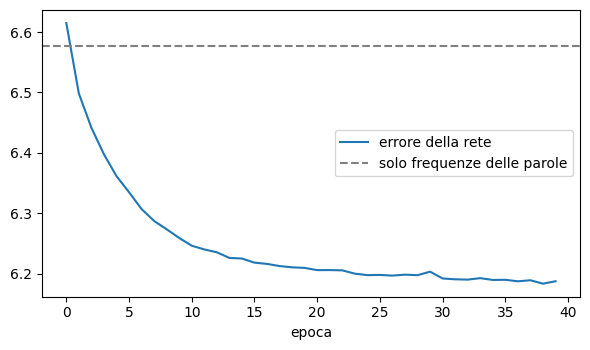

errore iniziale 6.61 → finale 6.19 | riferimento 6.58 | caso puro 7.65


In [10]:
prob_tieni = np.minimum(1, np.sqrt(1e-3 * frequenza_d.sum() / frequenza_d) + 1e-3 * frequenza_d.sum() / frequenza_d)

def addestra_parole(D=32, epoche=40, eta=5.0, B=128, seed=0):
    rng = np.random.default_rng(seed)
    W1 = rng.normal(scale=0.1, size=(V_d, D))
    W2 = rng.normal(scale=0.1, size=(D, V_d))
    b2 = np.zeros(V_d)
    errori, riferimento = [], None
    for e in range(epoche):
        scelta = rng.random(len(centri)) < np.minimum(prob_tieni[centri], prob_tieni[vicine_])
        ing, usc = centri[scelta], vicine_[scelta]
        ordine = rng.permutation(len(ing))
        ing, usc = ing[ordine], usc[ordine]
        if riferimento is None:
            q = np.bincount(usc, minlength=V_d) / len(usc)
            riferimento = -(q[q > 0] * np.log(q[q > 0])).sum()
        totale = 0
        for s in range(0, len(ing), B):
            a, t = ing[s:s + B], usc[s:s + B]
            h = W1[a]
            p = softmax(h @ W2 + b2)
            totale += -np.log(p[np.arange(len(t)), t]).sum()
            ds = p
            ds[np.arange(len(t)), t] -= 1
            ds /= len(t)
            dh = ds @ W2.T
            W2 -= eta * h.T @ ds
            b2 -= eta * ds.sum(axis=0)
            np.add.at(W1, a, -eta * dh)
        errori.append(totale / len(ing))
    return W1, errori, riferimento

W1_d, errori_d, riferimento_d = addestra_parole()

plt.figure(figsize=(6, 3.6))
plt.plot(errori_d, label='errore della rete')
plt.axhline(riferimento_d, color='gray', ls='--', label='solo frequenze delle parole')
plt.xlabel('epoca')
plt.legend()
plt.tight_layout()
plt.show()
print(f'errore iniziale {errori_d[0]:.2f} → finale {errori_d[-1]:.2f} | riferimento {riferimento_d:.2f} | caso puro {np.log(V_d):.2f}')

## Un momento di riflessione

- L'errore finale è molto più basso del caso puro, ma di poco rispetto al solo uso delle frequenze. Perché è un risultato ragionevole? Pensate all'esempio *luce → ?*: quante vicine plausibili ci sono?
- Il compito è davvero risolvibile al 100%? Che cosa dovrebbe sapere la rete?
- Il numero finale conta meno di quello che c'è nei vettori. Come possiamo controllare se i vettori hanno imparato qualcosa?

## Le parole vicine di Dante

Come prima, confrontiamo i vettori con la similarità del coseno. Guardiamo le vicine di alcune parole che nel poema hanno un ruolo preciso.

In [11]:
E_d = normalizza(W1_d)

def vicini_di(v, escludi=(), k=7):
    sim = E_d @ (v / np.linalg.norm(v))
    return [vocabolario_d[j] for j in np.argsort(-sim) if vocabolario_d[j] not in escludi][:k]

scelte_d = ['luce', 'amore', 'occhi', 'anima', 'fiamma', 'virgilio', 'beatrice', 'selva', 'pena']
print(pd.DataFrame({'parola': scelte_d,
                    'occorrenze': [freq_forme[p] for p in scelte_d],
                    'vicine': [', '.join(vicini_di(E_d[posizione_d[p]], (p,))) for p in scelte_d]}).to_string(index=False))

  parola  occorrenze                                                   vicine
    luce          81 etterna, viva, fiamma, donna, splendore, sustanza, amici
   amore          59 solo, accende, spirto, splendore, cielo, cammin, etterna
   occhi         212          miei, li, corti, attenti, altri, orecchi, erano
   anima          72        carca, parrebbe, trista, erba, val, bolgia, terza
  fiamma          37    punta, luce, compagnia, sponda, favilla, caccia, arco
virgilio          32      vinci, dicendo, stazio, bando, segni, breve, stesso
beatrice          43 ella, grado, intorno, riguardando, fuochi, fossa, piglio
   selva          18            ria, matera, esta, torre, persona, spada, ale
    pena          34      piaghe, salir, piede, intrar, simil, stanno, occhio


## Un momento di riflessione

- Per *luce*, *amore*, *occhi* le vicine hanno senso? Che cosa condividono con la parola di partenza: significato, grammatica, o il modo in cui Dante le usa insieme?
- Per *selva* e *virgilio* le vicine sono meno convincenti. Quante volte compaiono nel testo? Che cosa ci dice sul legame tra quantità di esempi e qualità del vettore?
- Il testo è del Trecento. Quanto di quello che troviamo è lingua italiana in generale e quanto è proprio di Dante?

## Le parole di Dante nel piano

Proiettiamo i vettori delle parole più frequenti nel piano con la PCA. Colorando le parole in base alla cantica in cui compaiono più spesso (rosso Inferno, blu Paradiso), possiamo vedere se la rete, che non ha mai ricevuto l'informazione su dove compare un verso, ha raccolto qualcosa di quella geografia.

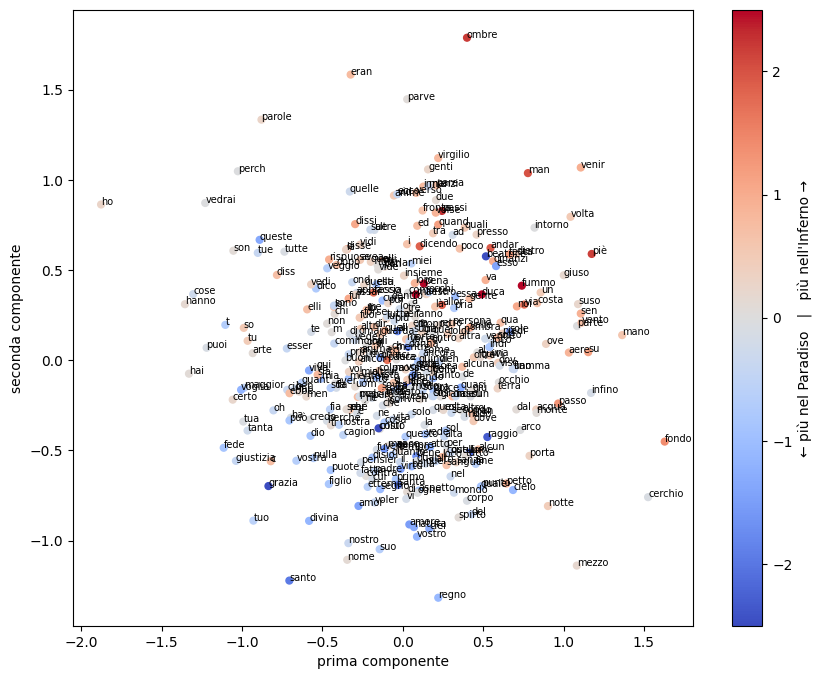

parole nel grafico: 384


In [12]:
frequenti_d = np.flatnonzero(frequenza_d >= 30)
conta_cantica = {c: collections.Counter() for c in set(nomi_canti)}
for c, canto in zip(nomi_canti, canti):
    conta_cantica[c].update(canto)
tot_cantica = {c: sum(n.values()) for c, n in conta_cantica.items()}

def quota_inferno(p):
    i = conta_cantica['inferno'][p] / tot_cantica['inferno']
    q = conta_cantica['paradiso'][p] / tot_cantica['paradiso']
    return np.log((i + 1e-5) / (q + 1e-5))

colore = np.array([quota_inferno(vocabolario_d[j]) for j in frequenti_d])
Ec = W1_d[frequenti_d] - W1_d[frequenti_d].mean(axis=0)
_, _, Vt = np.linalg.svd(Ec, full_matrices=False)
piano_d = Ec @ Vt[:2].T

fig, ax = plt.subplots(figsize=(10, 8))
sc = ax.scatter(piano_d[:, 0], piano_d[:, 1], c=colore, cmap='coolwarm', vmin=-2.5, vmax=2.5, s=24)
for k, j in enumerate(frequenti_d):
    ax.text(piano_d[k, 0], piano_d[k, 1], vocabolario_d[j], fontsize=7)
plt.colorbar(sc, label='← più nel Paradiso   |   più nell\'Inferno →')
ax.set_xlabel('prima componente')
ax.set_ylabel('seconda componente')
plt.show()
print('parole nel grafico:', len(frequenti_d))

## Un momento di riflessione

- Le parole del Paradiso (blu) e dell'Inferno (rosso) sono separate? Quali gruppi di parole si riconoscono?
- La rete ha mai visto il nome del canto o della cantica? Come ha ottenuto una separazione tra le parole di luoghi diversi?
- Quali parole hanno colori intermedi? Sono parole di tutto il poema? Dove stanno nel piano?
- Come nel notebook precedente, la separazione non è per classi decise da noi. Che cosa raggruppa le parole in questo piano?

## Sommare i vettori

I vettori sono numeri e si possono sommare. Se *luce* sta vicino alle parole con cui compare e *occhi* sta vicino alle sue, la somma dei due vettori cade vicino alle parole che compaiono sia con l'una sia con l'altra. Per ogni somma (e sottrazione) cerchiamo le parole più vicine al risultato, escludendo quelle di partenza.

In [13]:
def componi(positive, negative=(), k=7):
    v = sum(E_d[posizione_d[p]] for p in positive) - sum(E_d[posizione_d[p]] for p in negative)
    return ', '.join(vicini_di(v, tuple(positive) + tuple(negative), k))

espressioni = [(['occhi', 'luce'], []), (['fiamma', 'amore'], []), (['anima', 'luce'], []), (['cielo', 'luce'], ['terra'])]
righe = []
for pos_, neg_ in espressioni:
    nome = ' + '.join(pos_) + ''.join(f' − {n}' for n in neg_)
    righe.append({'operazione': nome, 'parole più vicine': componi(pos_, neg_)})
for p in ['occhi', 'luce']:
    righe.insert(0, {'operazione': p + ' (da sola)', 'parole più vicine': ', '.join(vicini_di(E_d[posizione_d[p]], (p,)))})
print(pd.DataFrame(righe).to_string(index=False))

          operazione                                                 parole più vicine
      luce (da sola)          etterna, viva, fiamma, donna, splendore, sustanza, amici
     occhi (da sola)                   miei, li, corti, attenti, altri, orecchi, erano
        occhi + luce etterna, splendore, potenza, veduta, creature, profonda, sustanza
      fiamma + amore             solo, accende, luce, legge, splendore, etterna, somma
        anima + luce                    alma, virtù, donna, vano, umane, etterna, esta
cielo + luce − terra     accende, valore, amore, fonte, sustanza, esperïenza, paradiso


## Un momento di riflessione

- Le parole vicine a *occhi + luce* sono vicine a *occhi*, a *luce*, o a entrambe? Che cosa significa, in termini di vettori, sommare due parole?
- *cielo + luce − terra* sposta il risultato verso l'alto, dove ci sono parole del Paradiso. Quanto è affidabile una sottrazione con vettori imparati su centomila parole?
- Ripetendo le somme con altre parole, quante danno un risultato interpretabile? Che cosa distingue le parole per cui funziona?

## Le analogie

Una proprietà più sorprendente è la **differenza**: se i vettori sono organizzati bene, il passaggio da *padre* a *madre* dovrebbe somigliare al passaggio da *figlio* a *figlia*. Allora l'analogia

$$\text{padre} : \text{madre} = \text{figlio} : ?$$

si risolve cercando la parola più vicina a $v_{\text{madre}} - v_{\text{padre}} + v_{\text{figlio}}$. Proviamo con i vettori di Dante.

In [14]:
def analogia(a, b, c, E=None, vocab=None, k=5, ammessi=None):
    E = E_d if E is None else E
    vocab = vocabolario_d if vocab is None else vocab
    p = {w: i for i, w in enumerate(vocab)}
    q = E[p[b]] - E[p[a]] + E[p[c]]
    sim = E @ (q / np.linalg.norm(q))
    for w in (a, b, c):
        sim[p[w]] = -9
    if ammessi is not None:
        sim = np.where(ammessi, sim, -9)
    return ', '.join(vocab[j] for j in np.argsort(-sim)[:k])

prove = [('padre', 'madre', 'figlio'), ('re', 'regina', 'uomo'), ('santo', 'santa', 'figlio'),
         ('vita', 'morte', 'bene'), ('giorno', 'notte', 'luce'), ('cielo', 'terra', 'sopra')]
print(pd.DataFrame([{'analogia': f'{a} : {b} = {c} : ?', 'risposte di Dante': analogia(a, b, c)} for a, b, c in prove]).to_string(index=False))

                  analogia                      risposte di Dante
padre : madre = figlio : ? chiamata, prende, feroce, bianca, alte
    re : regina = uomo : ?  pace, misura, dintorno, grotta, ficca
santo : santa = figlio : ?   coda, giunse, trista, fianco, feroce
   vita : morte = bene : ?      crede, taci, altr, dicesse, tempo
 giorno : notte = luce : ?  vita, costui, preda, affezion, miglia
 cielo : terra = sopra : ?              meno, di, n, color, beata


## Un momento di riflessione

- Quale parola ci aspetteremmo per ognuna di queste analogie? Compare tra le prime cinque risposte?
- Con vettori che funzionano bene per le vicinanze, l'analogia non funziona. Che cosa serve in più? Pensate a quante volte *padre* e *madre* compaiono nello stesso verso, e a quante volte *figlia* sta vicino a *madre*.
- Un'analogia è una proprietà di tutti i vettori, non di quattro parole. Come possiamo misurarla su molti esempi, e non solo su qualche prova scelta?

## Misurare le analogie, e cambiare i vettori

Costruiamo un insieme di coppie opposte o parallele (maschile/femminile, contrari) presenti nel vocabolario di Dante, e per ogni coppia di coppie $(a:b)$, $(c:d)$ chiediamo se $d$ è tra le prime cinque risposte per $a : b = c : ?$. Come confronto usiamo vettori casuali e i vettori di spaCy (**300 dimensioni**, appresi con lo stesso principio, ma su una quantità enorme di testo italiano contemporaneo, non su centomila parole). Per un confronto equo, tutti cercano la risposta solo tra le parole del vocabolario di Dante.

In [15]:
import itertools

sp_d = np.array([nlp.vocab[p].vector for p in vocabolario_d])
ha_vettore = np.linalg.norm(sp_d, axis=1) > 0
sp_d = normalizza(sp_d)

coppie = [('padre', 'madre'), ('figlio', 'figlia'), ('santo', 'santa'), ('re', 'regina'), ('uomo', 'donna'),
          ('bene', 'male'), ('vita', 'morte'), ('giorno', 'notte'), ('cielo', 'terra'), ('alto', 'basso'),
          ('pace', 'guerra'), ('luce', 'ombra'), ('sole', 'luna'), ('anima', 'corpo'), ('amore', 'odio'),
          ('salire', 'scendere'), ('vero', 'falso'), ('primo', 'ultimo'), ('dolce', 'amaro'), ('caldo', 'freddo'),
          ('dentro', 'fuori'), ('sopra', 'sotto'), ('nuovo', 'vecchio'), ('lungo', 'breve')]
coppie = [c for c in coppie if all(p in posizione_d and ha_vettore[posizione_d[p]] for p in c)]

def quota_analogie(M, k=5):
    giuste = totale = 0
    for (a, b), (c, d) in itertools.permutations(coppie, 2):
        q = M[posizione_d[b]] - M[posizione_d[a]] + M[posizione_d[c]]
        sim = M @ q
        sim[[posizione_d[a], posizione_d[b], posizione_d[c]]] = -9
        sim[~ha_vettore] = -9
        giuste += posizione_d[d] in np.argsort(-sim)[:k]
        totale += 1
    return giuste / totale

casuali_d = normalizza(np.random.default_rng(0).normal(size=(V_d, 32)))
print(len(coppie), 'coppie,', len(coppie) * (len(coppie) - 1), 'analogie')
print(pd.Series({'vettori casuali': quota_analogie(casuali_d),
                 'vettori di Dante (32 dimensioni, 100 mila parole)': quota_analogie(E_d),
                 'vettori di spaCy (300 dimensioni, molto più testo)': quota_analogie(sp_d)}).round(3).to_string())
print('\nprobabilità di indovinare a caso:', round(5 / ha_vettore.sum(), 4))

24 coppie, 552 analogie


vettori casuali                                       0.004
vettori di Dante (32 dimensioni, 100 mila parole)     0.022
vettori di spaCy (300 dimensioni, molto più testo)    0.605

probabilità di indovinare a caso: 0.0025


## Un momento di riflessione

- Quanto vale la quota con i vettori di Dante, rispetto al caso? E con quelli di spaCy?
- Che cosa è cambiato tra i due: l'algoritmo, la quantità di testo, il numero di dimensioni? Perché la quantità di testo conta per una proprietà come questa?
- Che cosa significa che *madre − padre* è «circa uguale» a *figlia − figlio*? Che cosa ha dovuto vedere la rete, in tutti quei testi, per organizzarsi così?
- I vettori di spaCy sono stati addestrati su testi di oggi. Che cosa succederà se li applichiamo a un'analogia che riguarda il mondo di Dante?

In [16]:
prove2 = [('padre', 'madre', 'figlio'), ('re', 'regina', 'uomo'), ('santo', 'santa', 'figlio'),
          ('bene', 'male', 'vero'), ('giorno', 'notte', 'luce'), ('alto', 'basso', 'salire'),
          ('paradiso', 'inferno', 'luce'), ('paradiso', 'inferno', 'cielo'), ('bene', 'male', 'amore')]
righe = []
for a, b, c in prove2:
    if all(p in posizione_d and ha_vettore[posizione_d[p]] for p in (a, b, c)):
        righe.append({'analogia': f'{a} : {b} = {c} : ?', 'risposte di spaCy': analogia(a, b, c, E=sp_d, ammessi=ha_vettore)})
print(pd.DataFrame(righe).to_string(index=False))

                      analogia                          risposte di spaCy
    padre : madre = figlio : ?    figlia, sorella, figli, donna, famiglia
        re : regina = uomo : ?     donna, anima, femmina, amore, creatura
    santo : santa = figlio : ?       figlia, sorella, madre, padre, figli
        bene : male = vero : ? peccato, falso, demonio, crudele, doloroso
     giorno : notte = luce : ?          nebbia, lucerna, luna, luci, nube
     alto : basso = salire : ?   scendere, salir, scender, cadere, salita
 paradiso : inferno = luce : ?    ombra, lucerna, oscura, angoscia, ombre
paradiso : inferno = cielo : ?     abisso, nferno, tenebre, ombra, fiamme
       bene : male = amore : ?        amor, odio, uomo, inferno, angoscia


## Un momento di riflessione

- Per le prime analogie, la risposta di spaCy è quella che ci aspettavamo? In quale posizione?
- *paradiso : inferno = luce : ?* e *paradiso : inferno = cielo : ?*: le risposte sono quelle che Dante avrebbe dato? Che cosa ha imparato spaCy su queste parole, e da quali testi?
- La somma, la differenza e l'analogia funzionano perché la rete ha organizzato lo spazio in **direzioni** (maschile-femminile, bene-male). Ma nessuno gliele ha chieste. Da dove vengono?
- Che cosa dobbiamo concludere sul rapporto tra il compito (prevedere vicine), la quantità di dati e le proprietà dei vettori che troviamo alla fine?

## Lo stesso modello, un altro testo

I vettori dipendono dai testi su cui sono stati appresi. Per vederlo, partiamo dal modello addestrato su Dante e **continuiamo l'addestramento** su un testo diversissimo: settecento ricette di cucina. Questa operazione si chiama **fine-tuning**. Il vocabolario è condiviso tra i due testi (le tremila parole più frequenti nell'insieme). Le parole che non compaiono nelle ricette non vengono più aggiornate: restano come le aveva lasciate Dante.

Per ogni stadio guardiamo le parole più vicine, cercandole solo tra quelle che il modello ha incontrato fino a quel momento.

In [17]:
ricette = pd.read_csv('/Users/Flint/Data/recipes/it_recipes.csv').sample(frac=1, random_state=0)
testi_ricette = [re.findall(r"[^\W\d_]+", str(s).lower()) for s in ricette['Steps'].head(700)]

freq_u = collections.Counter(p for t in canti + testi_ricette for p in t)
vocabolario_u = [p for p, _ in freq_u.most_common(3000)]
posizione_u = {p: j for j, p in enumerate(vocabolario_u)}
V_u = len(vocabolario_u)
frequenza_u = np.array([freq_u[p] for p in vocabolario_u], dtype=float)
prob_tieni_u = np.minimum(1, np.sqrt(1e-3 * frequenza_u.sum() / frequenza_u) + 1e-3 * frequenza_u.sum() / frequenza_u)

def coppie_di(testi, finestra=3):
    c, v = [], []
    for t in testi:
        ids = [posizione_u[p] for p in t if p in posizione_u]
        for k, i in enumerate(ids):
            for j in range(max(0, k - finestra), min(len(ids), k + finestra + 1)):
                if j != k:
                    c.append(i)
                    v.append(ids[j])
    return np.array(c), np.array(v)

def addestra_su(c, v, aggiornamenti, par=None, D=32, eta=5.0, B=128, seed=0):
    rng = np.random.default_rng(seed)
    if par is None:
        W1 = rng.normal(scale=0.1, size=(V_u, D)); W2 = rng.normal(scale=0.1, size=(D, V_u)); b2 = np.zeros(V_u)
    else:
        W1, W2, b2 = (a.copy() for a in par)
    fatti = 0
    while fatti < aggiornamenti:
        scelta = rng.random(len(c)) < np.minimum(prob_tieni_u[c], prob_tieni_u[v])
        ing, usc = c[scelta], v[scelta]
        ordine = rng.permutation(len(ing))[:aggiornamenti - fatti]
        ing, usc = ing[ordine], usc[ordine]
        for s in range(0, len(ing), B):
            a, t = ing[s:s + B], usc[s:s + B]
            h = W1[a]
            ds = softmax(h @ W2 + b2)
            ds[np.arange(len(t)), t] -= 1
            ds /= len(t)
            dh = ds @ W2.T
            W2 -= eta * h.T @ ds
            b2 -= eta * ds.sum(axis=0)
            np.add.at(W1, a, -eta * dh)
        fatti += len(ing)
    return W1, W2, b2

c_dante, v_dante = coppie_di(canti)
c_ric, v_ric = coppie_di(testi_ricette)
print('coppie da Dante:', len(c_dante), '| coppie dalle ricette:', len(c_ric))

par_dante = addestra_su(c_dante, v_dante, 5_000_000)
par_ricette = addestra_su(c_ric, v_ric, 2_500_000, par=par_dante, eta=2.0)

conta_dante = collections.Counter(p for t in canti for p in t)
conta_ric = collections.Counter(p for t in testi_ricette for p in t)
visto_dante = np.array([conta_dante[p] > 0 for p in vocabolario_u])
visto_dopo = visto_dante | np.array([conta_ric[p] > 0 for p in vocabolario_u])
print('parole del vocabolario viste in Dante:', visto_dante.sum(), '| viste dopo le ricette:', visto_dopo.sum())

coppie da Dante: 496710 | coppie dalle ricette: 818550


parole del vocabolario viste in Dante: 1807 | viste dopo le ricette: 3000


## Un momento di riflessione

- Il modello ha fatto un altro passaggio di addestramento sullo stesso compito, con un testo diverso. Che cosa ci aspettiamo che cambi nei vettori?
- Quali parole non vengono modificate dal secondo addestramento? Perché?

In [18]:
En_dante = normalizza(par_dante[0])
En_ric = normalizza(par_ricette[0])

def vicine_in(En, parola, visto, k=6):
    sim = En @ En[posizione_u[parola]]
    sim = np.where(visto, sim, -9)
    sim[posizione_u[parola]] = -9
    return ', '.join(vocabolario_u[j] for j in np.argsort(-sim)[:k])

parole_u = ['sale', 'carne', 'fuoco', 'luce', 'acqua', 'vino', 'mano', 'tavola']
print(pd.DataFrame({'parola': parole_u,
                    'vicine, solo Dante': [vicine_in(En_dante, p, visto_dante) for p in parole_u],
                    'vicine, dopo le ricette': [vicine_in(En_ric, p, visto_dopo) for p in parole_u]}).to_string(index=False))

coppie_u = [('sale', 'sole'), ('sale', 'pepe'), ('carne', 'anima'), ('carne', 'pancetta'),
            ('fuoco', 'fiamma'), ('fuoco', 'fornello'), ('luce', 'etterna'), ('luce', 'spento')]
print()
print(pd.DataFrame([{'coppia': f'{a} – {b}',
                     'similarità, solo Dante': round(float(En_dante[posizione_u[a]] @ En_dante[posizione_u[b]]), 2),
                     'similarità, dopo le ricette': round(float(En_ric[posizione_u[a]] @ En_ric[posizione_u[b]]), 2)}
                    for a, b in coppie_u]).to_string(index=False))

non_toccate = ~np.array([conta_ric[p] > 0 for p in vocabolario_u]) & visto_dante
spostamento = (En_dante * En_ric).sum(axis=1)
print('\nparole di Dante assenti dalle ricette (vettore identico):', non_toccate.sum(),
      '| similarità media tra vecchio e nuovo vettore delle altre:', round(float(spostamento[~non_toccate & visto_dopo].mean()), 2))

parola                               vicine, solo Dante                                          vicine, dopo le ricette
  sale      pane, mille, veduto, strada, averle, rimaso   macinata, macinato, cannella, pizzico, pangrattato, insaporite
 carne      chiara, argomento, spene, la, tesoro, somma pancetta, dopodichè, marinatura, besciamella, salsiccia, passata
 fuoco              qualche, se, carni, sarai, sai, dei               fornello, medio, dolce, bollore, fiamma, rimettete
  luce etterna, viva, fontana, trita, scrittura, fiamma                   accesa, spento, ore, cuoceteli, bassa, statico
 acqua           amor, altra, duri, avrà, fredda, fiori         tiepida, abbondante, ebollizione, fredda, bagnate, getto
  vino      cui, à, quando, intanto, sufficiente, angel             evaporare, aceto, evaporato, bianco, pepate, sfumate
  mano      costui, ombra, gran, diece, montare, cesare                     man, velocemente, così, li, formare, maniera
tavola       stata, stella, meco

## Un momento di riflessione

- *sale*, *carne*, *fuoco*, *luce*: che cosa significano nei due testi? Le parole vicine cambiano? Sono cambiate in modo sensato?
- Per le coppie *sale – sole* e *sale – pepe*, che cosa è successo alla similarità? Lo stesso modello dice cose diverse della stessa parola.
- Dopo le ricette, il modello ricorda ancora Dante? Che cosa è rimasto, e che cosa è stato sovrascritto? Le parole che non compaiono nelle ricette hanno ancora un significato «dantesco»?
- Nessun vettore è giusto in assoluto: quello che una parola «significa» per il modello dipende dai testi su cui è stato allenato. Che conseguenze ha, se usiamo vettori già addestrati (come quelli di spaCy) su un testo diverso da quelli di addestramento?

## Cosa abbiamo visto

1. Il **contesto** di una parola è l'insieme delle parole vicine. Ogni posizione di ogni testo diventa un esempio di addestramento, **senza etichette** date da una persona.
2. La rete prevede la parola dal suo contesto: l'ingresso è la media dei vettori delle parole di contesto, il livello intermedio ha 16 dimensioni, l'uscita ha una classe per ogni parola.
3. Con il training la rete impara a prevedere anche contesti nuovi: la probabilità si concentra su parole che nel testo compaiono in posti simili (*caldo*, *freddi*).
4. Quello che la rete ha imparato sta nei **vettori delle parole** (le righe di $W_1$). Parole usate negli stessi contesti hanno vettori vicini: *umido* è vicina a *afoso*, *giugno* a *maggio* e *luglio*, *freddi* a *gelidi* e *rigidi*.
5. Rispetto al vettore per classe, il vettore da contesto cattura, almeno in parte, un significato più **generale**: somiglianze grammaticali e di campo semantico che le cinque etichette non potevano contenere.
6. Il risultato è limitato dalla quantità di dati: con meno di tremila parole di testo i vettori sono rumorosi. Con molto più testo è ciò che si chiama **word embedding**.

7. Si può anche invertire il compito: da una parola, prevedere una delle sue **vicine**. Sulla *Commedia* (centomila parole) i vettori ottenuti raccolgono campi di parole (*luce*, *etterna*, *splendore*, *sustanza*) e permettono **somme** sensate (*occhi + luce*).
8. Proprietà come la **differenza** e l'**analogia** (*madre − padre + figlio ≈ figlia*) richiedono molto più testo: su Dante la quota di analogie giuste è vicina al caso, con i vettori di spaCy (altro testo, 300 dimensioni) supera la metà.

9. I vettori dipendono dai testi su cui sono addestrati: continuando l'addestramento su un testo diverso (ricette), le vicine di una parola cambiano (*sale* passa da *sole* a *pepe*), mentre le parole assenti dal nuovo testo restano come prima.

Restano aperte alcune domande su come procedere:

- **Più testo, più dimensioni.** Vettori utili si ottengono con milioni di frasi e centinaia di dimensioni. Come si scelgono dimensione e finestra?
- **Una parola, un vettore.** *banco* ha sempre lo stesso vettore, di scuola o di pesci. Come si fa a far dipendere il vettore dal contesto della singola frase?
- **L'ordine delle parole.** La media dei vettori non distingue «il cane morde l'uomo» da «l'uomo morde il cane». Che cosa serve per tenerne conto?
- **Usare i vettori per altri compiti.** I vettori appresi su un compito si possono riutilizzare per classificare testi o cercarli? Che cosa si guadagna rispetto a partire da zero?